# Lista 3 metoda akceptacji-odrzucenia, metoda Boxa-Mullera oraz dekompozycja choleskiego

In [2]:
import numpy as np 
import scipy 
import matplotlib.pyplot as plt 
from decimal import Decimal

## Zadanie 2. 
Niech naszym rozkładem pomocnicznym będzie rozkład dyskretny równomierny przyjmujący wartości: 1,2,3,4,5. 

#### Metoda tablicowa 

In [3]:

def count_decimals(num_list):
    max_digits = -999
    for i in num_list:
        d = Decimal(str(i))
        exponent = abs(d.as_tuple().exponent)
        if max_digits < exponent:
            max_digits = exponent
    return max_digits

def look_up_table (values=[1,2,3,4,5], prob=[0.11,0.12,0.27,0.19,0.31], max_iter = 10000, size = 1000):
    """Values - sorted list with all ints between values[0] to values[-1] - randint distr in this interval"""
    decimals = count_decimals(prob)
    multiplier = 10 ** decimals

    prob_counts = [int(round(p * multiplier)) for p in prob]
    prob_table = np.zeros(multiplier, dtype=int)


    cur_pos = 0
    for index, count in enumerate(prob_counts):
        prob_table[cur_pos:cur_pos + count] += values[index]
        cur_pos += count

    return prob_table 

look_up_table (values=[1,2], prob=[0.5,0.5])
look_up_table ()

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4,
       4, 4, 4, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5,
       5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5])

### generowanie zmiennej z rozkładu gamma(3,2) metodą akceptacji odrzucenia

In [4]:
def gamma_pdf(x, alpha,theta):
    return (1 / (scipy.special.gamma(alpha)*theta**alpha)) * x**(alpha -1) * np.exp(-x/theta)


def gamma_acept_rej(alpha=3, theta=2, size=1000):
    # i will use exponential distr 
    c = 27 * np.exp(-2) # should be calculated manually 
    results = []
    while len(results) < size:
        batch_size = int((size - len(results)) * c * 1.1) + 10
        u = np.random.uniform(size=batch_size)
        y_values = scipy.stats.expon.rvs(scale=alpha, size=batch_size)

        mask = u <= gamma_pdf(y_values, alpha=alpha, theta=theta) / (c * scipy.stats.expon.pdf(y_values, scale=alpha)) # scale should be calculated manually as well
        accepted = y_values[mask]
        results.extend(accepted)
    
    return np.array(results[:size -1])

gamma_sample = gamma_acept_rej(size=10000)

Sprawdźmy poprawność generatora

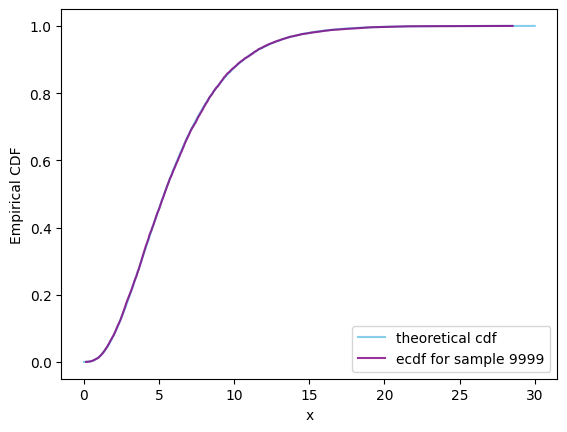

In [5]:
from list_2_func import drawdemp
arguments = np.linspace(0, 30, 1000)
F = scipy.stats.gamma.cdf(arguments, a=3, scale=2)
plt.plot(arguments, F, label="theoretical cdf", color="skyblue")
drawdemp(gamma_sample)

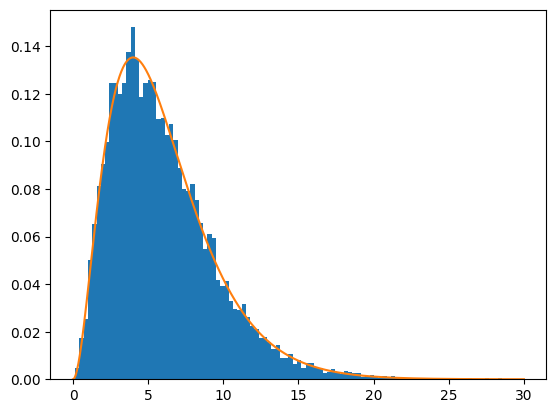

In [6]:
plt.hist(gamma_sample, density=True, bins=100)
f = scipy.stats.gamma.pdf(arguments, a=3, scale=2)
plt.plot(arguments, f, label="theoretical pdf")

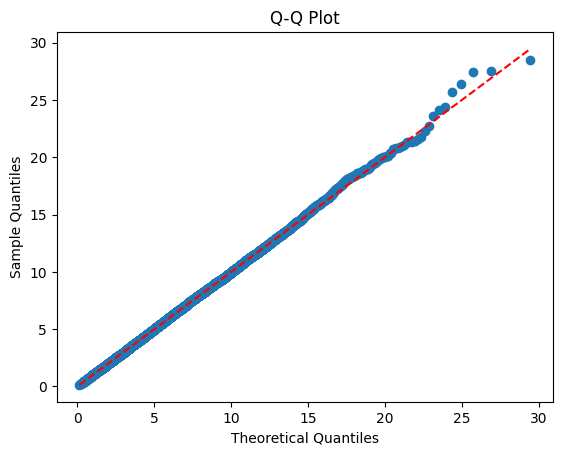

In [7]:
from list_2_func import drawqq

drawqq(gamma_sample, lambda x: scipy.stats.gamma.ppf(x, a=3, scale=2) )

In [8]:
print(f"{np.mean(gamma_sample)} - średnia próbkowa, {np.var(gamma_sample)} - wariancja próbkowa")
print(f"{scipy.stats.gamma.mean(a=3, scale=2)} - średnia teoretyczna, {scipy.stats.gamma.var(a=3,scale=2)} - średnia próbkowa")

6.004451546807805 - średnia próbkowa, 12.151139065691138 - wariancja próbkowa
6.0 - średnia teoretyczna, 12.0 - średnia próbkowa


## b)

In [9]:
def acept_rej_disc(values=[1,2,3,4,5], prob=[0.11,0.12,0.27,0.19,0.31], max_iter = 10000, size = 10000):
    """values array have to be filled with ints and distance between values are 1"""
    values = np.array(values)
    p = np.array(prob)

    # Uniform distrbution
    k = len(values)
    q_i = 1/ k # probabilit of each value
    
    c = np.max(p / q_i)

    results = []

    while len(results) < size:
        batch_size = int((size - len(results)) * c * 1.1 + 10) # we want batch longer than the results we want due to rejection.
        y_indices = np.random.randint(min(values), max(values) + 1, size=batch_size)

        u = np.random.uniform(size=batch_size)

        # acceptance ratio 
        acceptance_ratio = p[y_indices - 1] / (c * q_i)

        mask = u <= acceptance_ratio

        accepted = y_indices[mask]
        results.extend(accepted)
    return np.array(results[:size])

sample_size = 10000
values = [1,2,3,4,5]
prob = [0.11, 0.12, 0.27, 0.19,0.31]
discrete_sample =acept_rej_disc(values = values, prob=prob, size=sample_size)
print(len(discrete_sample))
print(discrete_sample)
batch_prob = np.bincount(discrete_sample)/sample_size

res = scipy.stats.ecdf(discrete_sample)
print(res.cdf.probabilities) 

10000
[5 5 5 ... 2 5 5]
[0.1103 0.231  0.5083 0.6971 1.    ]


Sprawdzenie generatora rozkładu dyskretnego 

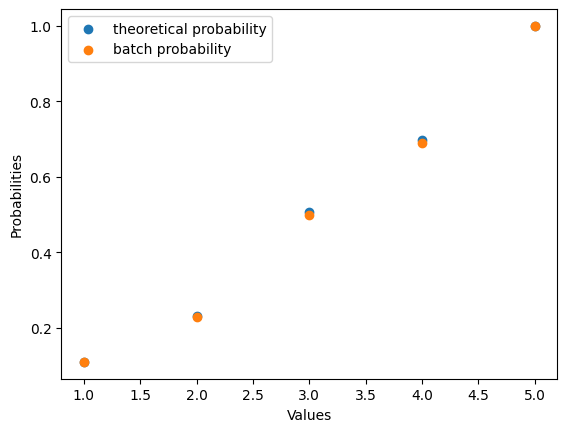

In [10]:
ax = plt.subplot()
ax.scatter(values, res.cdf.probabilities, label="theoretical probability")
ax.set_xlabel('Values')
ax.set_ylabel('Probabilities')
ax.scatter(values, np.cumsum(prob), label="batch probability")
plt.legend()
plt.show()

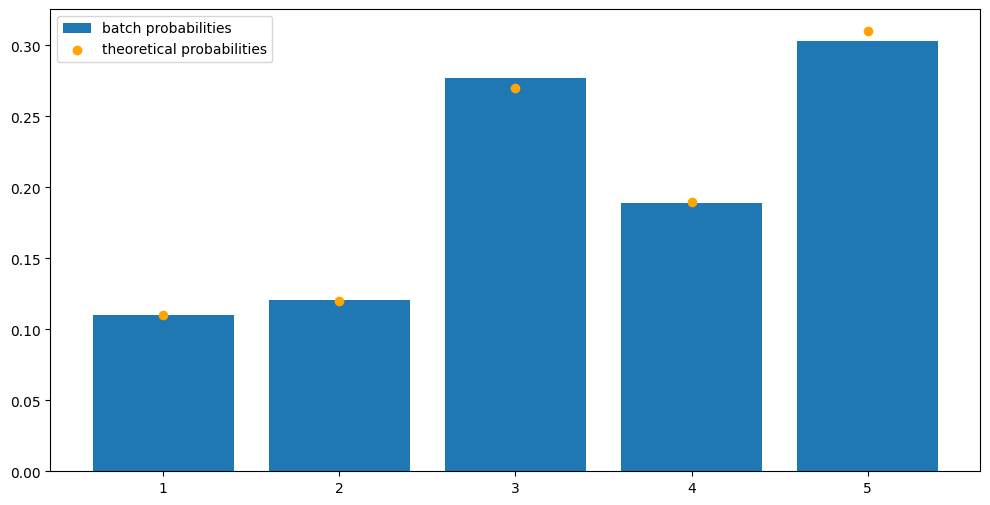

In [11]:

# centring the histograms around the ints
bins = np.arange(min(discrete_sample), max(discrete_sample) + 2) - 0.5

fig, ax = plt.subplots(figsize=(12,6))
ax.hist(discrete_sample, bins=bins, density=True,rwidth=0.8, label = "batch probabilities")
ax.scatter(values, prob, label = "theoretical probabilities", color='orange')

ax.legend()

plt.show()

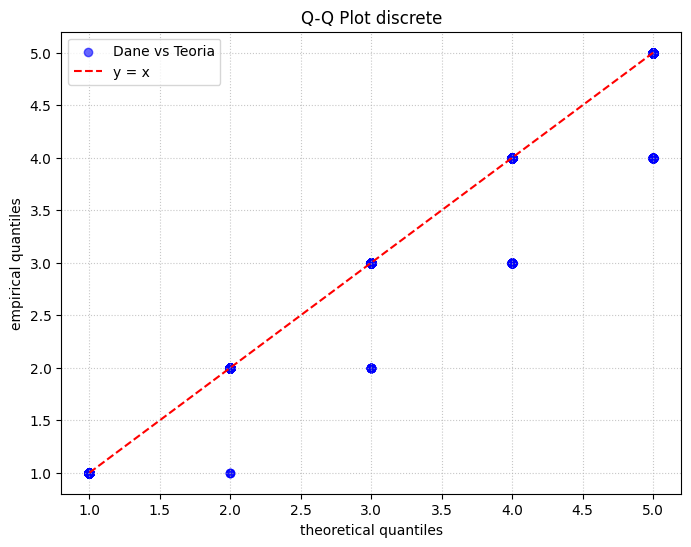

In [12]:
from list_2_func import drawqq_discrete

drawqq_discrete(discrete_sample, probs=prob, values=values)

In [13]:
print(f"{np.mean(discrete_sample)} - średnia próbkowa, {np.var(discrete_sample)} - wariancja próbkowa")
theoretical_mean = np.sum(np.array(values) * np.array(prob))
theoretical_mean_sq = np.sum(np.power(np.array(values), 2) * np.array(prob))
theoretical_variance = theoretical_mean_sq - theoretical_mean**2
print(f"{theoretical_mean} - średnia teoretyczna, {theoretical_variance} - wariancja teoretyczna")

3.4533 - średnia próbkowa, 1.7568191100000004 - wariancja próbkowa
3.47 - średnia teoretyczna, 1.7691 - wariancja teoretyczna


### Zadanie 3. 
Zróbię klasę która będzie generatorem metody akceptacji odrzucenia, musimy tylko podać odpowiednie funkcję i wartość c. 

In [14]:
class Accept_Rej_Method:
    def __init__(self, f_pdf,g_pdf,g_gen, c):
        self.f_pdf = f_pdf
        self.g_pdf = g_pdf
        self.g_gen = g_gen
        self.c = c 
    
    def generate_sample(self, size): 
        results =[]

        while size > len(results):
            batch_size = int((size - len(results)) * self.c * 1.1 + 10) # we want batch longer than the results we want due to rejection.
            y_candidates = self.g_gen(size=batch_size)

            u = np.random.uniform(size=batch_size)

            # acceptance ratio 
            acceptance_ratio = self.f_pdf(y_candidates) / (self.c * self.g_pdf(y_candidates))

            mask = u <= acceptance_ratio

            accepted = y_candidates[mask]
            results.extend(accepted)
        return np.array(results[:size])
    
def a_pdf(x):
    return 3/2 * (1-np.pow(x,2))

def a_cdf(x):
    return 3/2 * x- 1/2 * x**3

def b_pdf(x):
    return 3/2 * np.sin(x) * np.pow(np.cos(x), 2)

def b_cdf(x):
    return 1/2 - np.pow(np.cos(x), 3)/2

def c_pdf(x):
    return 2* np.sqrt(1/(2*np.pi)) * np.pow(np.e, (-x**2)/2)
def c_cdf(x):
    return 2 * scipy.stats.norm.cdf(x) - 1

#### a) 

In [15]:
sample_size = 100000

a_func = Accept_Rej_Method(f_pdf = a_pdf, g_pdf= lambda x: 1,g_gen= lambda size: np.random.uniform(low=0, high=1, size=size) , c=3/2)

a_sample = a_func.generate_sample(sample_size)

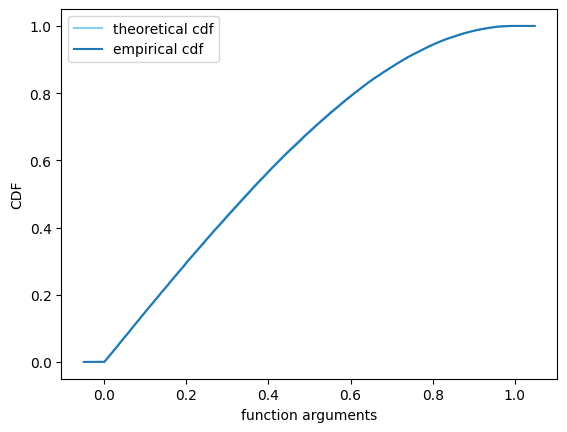

In [16]:
arguments = np.linspace(0,1,5000)
fig,ax = plt.subplots()
ax.plot(arguments, a_cdf(arguments), color="skyblue", label="theoretical cdf")
res = scipy.stats.ecdf(a_sample)
res.cdf.plot(ax, label="empirical cdf")
#drawdemp(a_sample)
ax.set_ylabel('CDF')
ax.set_xlabel("function arguments")
plt.legend()
plt.show()

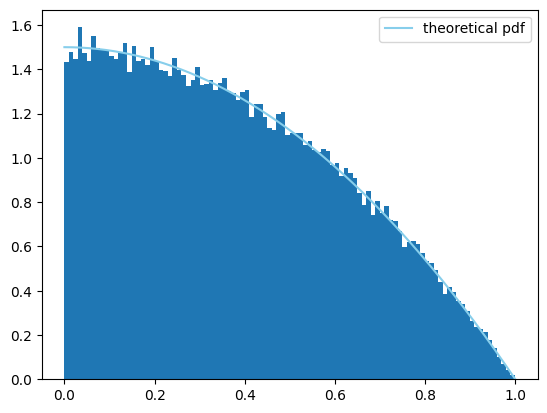

In [17]:
plt.hist(a_sample, density=True, bins=100)
plt.plot(arguments, a_pdf(arguments), label="theoretical pdf", color="skyblue")
plt.legend()
plt.show()

0.3472963744421584


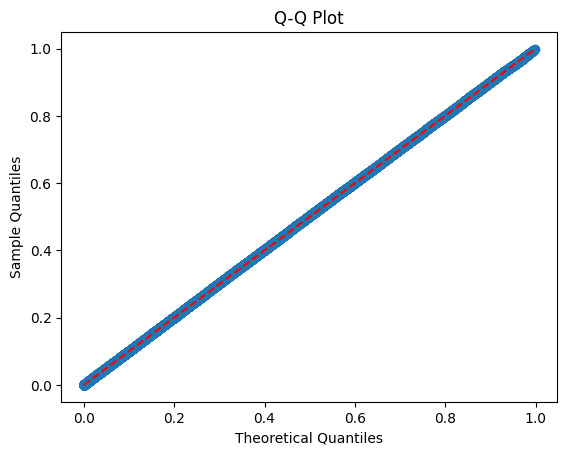

In [18]:
def get_a_ppf():
    """Returns a function that acts as the Percent Point Function (Inverse CDF)"""
    # 1. Create a fine mesh of points in the domain [0, 1]
    x_fine = np.linspace(0, 1, 1000)
    
    # 2. Calculate the corresponding CDF values
    cdf_values = a_cdf(x_fine)
    
    # 3. Use interpolation to swap axes: map CDF probability -> x value
    # bounds_error=False ensures we don't crash if p is exactly 0 or 1
    return scipy.interpolate.interp1d(cdf_values, x_fine, bounds_error=False, fill_value=(0, 1))

a_ppf = get_a_ppf()
print(a_ppf(1/2))
print(a_ppf)
drawqq(a_sample, a_ppf)

In [19]:
print(f"{np.mean(a_sample)} - średnia próbkowa, {np.var(a_sample)} - wariancja próbkowa")
ex = scipy.integrate.quad(lambda x: x * a_pdf(x), 0,1)
ex2 = scipy.integrate.quad(lambda x: np.pow(x,2) * a_pdf(x), 0,1)
mean = ex[0]
var = -np.pow(ex[0], 2) + ex2[0]
print(f"{mean} - theoretical mean, {var} - theoretical variance")

0.3763779677687881 - średnia próbkowa, 0.059452065710416176 - wariancja próbkowa
0.375 - theoretical mean, 0.05937499999999998 - theoretical variance


b) rozkład pomocniczy - jednostajny od 0 do pi 

In [20]:
b_sample_size =1000000
b_func = Accept_Rej_Method(f_pdf = b_pdf, g_pdf= lambda x: 1/np.pi, g_gen= lambda size: np.random.uniform(low=0, high=np.pi, size=size) , c=3*np.pi/2)
b_sample = b_func.generate_sample(b_sample_size)
print(b_sample)

[0.93923595 2.36298637 0.07129991 ... 2.31336227 0.8022832  0.50524246]


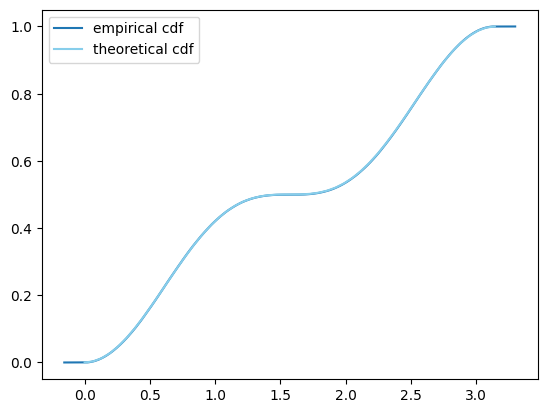

In [21]:
arguments = np.linspace(0, np.pi, 50)
res= scipy.stats.ecdf(b_sample)

fig,ax = plt.subplots()
res.cdf.plot(ax, label="empirical cdf")
plt.plot(arguments, b_cdf(arguments), color="skyblue", label= "theoretical cdf")
plt.legend()

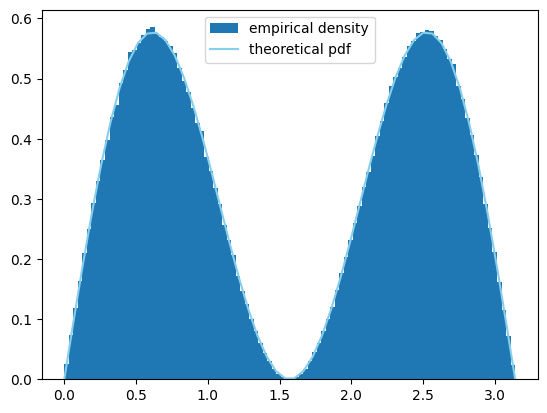

In [22]:
plt.hist(b_sample, density=True, label="empirical density", bins=100)
plt.plot(arguments, b_pdf(arguments), label="theoretical pdf", color="skyblue")
plt.legend()

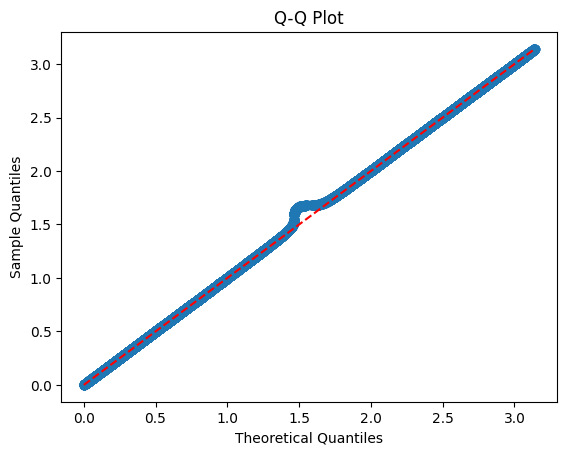

In [23]:
def get_b_ppf():
    """Returns a function that acts as the Percent Point Function (Inverse CDF)"""
    # 1. Create a fine mesh of points in the domain [0, 1]
    x_fine = np.linspace(0, np.pi, 3000)
    
    # 2. Calculate the corresponding CDF values
    cdf_values = b_cdf(x_fine)
    
    # 3. Use interpolation to swap axes: map CDF probability -> x value
    # bounds_error=False ensures we don't crash if p is exactly 0 or 1
    return scipy.interpolate.interp1d(cdf_values, x_fine, bounds_error=False, fill_value=(0, np.pi))
b_ppf = get_b_ppf()

drawqq(b_sample, b_ppf)

In [24]:
ex = scipy.integrate.quad(lambda x: x * b_pdf(x), 0,np.pi)
ex2 = scipy.integrate.quad(lambda x: np.pow(x,2) * b_pdf(x), 0,np.pi)
print(f"{np.mean(b_sample)} - średnia próbkowa, {np.var(b_sample)} - wariancja próbkowa")
print(f"{ex[0]} - teoretyczna srednia, {-np.pow(ex[0],2) + ex2[0]} - wariancja teoretyczna")

1.5719909470323556 - średnia próbkowa, 0.9122514247960188 - wariancja próbkowa
1.5707963267948966 - teoretyczna srednia, 0.9118455447167833 - wariancja teoretyczna


c) rozkład pomocniczy wykładniczy z parametrem lambda = 2 

In [25]:
from list_2_func import generate_expon_sample
sample_size = 1000000

c_func = Accept_Rej_Method(f_pdf = c_pdf, g_pdf= lambda x: 2 * np.exp(-2 * x) ,g_gen= lambda size: generate_expon_sample(size=size, lamb=2) ,
                           c=1/np.sqrt(2 * np.pi) * np.exp(2))

c_sample = c_func.generate_sample(sample_size)

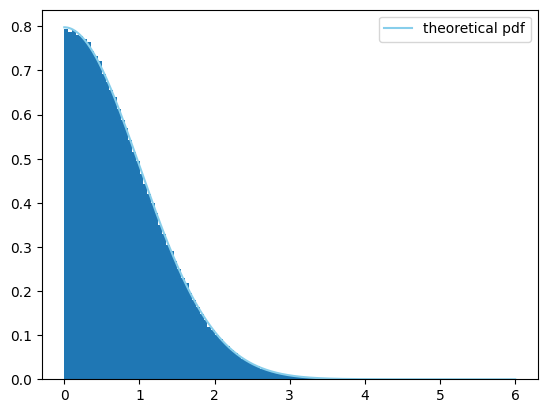

In [26]:
plt.hist(c_sample, density=True, bins=100)
arguments = np.linspace(0, 6, 1000)
plt.plot(arguments, c_pdf(arguments), label="theoretical pdf", color="skyblue")
plt.legend()

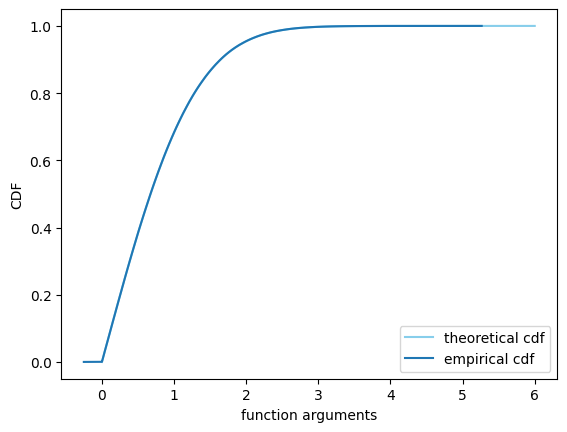

In [27]:
fig,ax = plt.subplots()
ax.plot(arguments, c_cdf(arguments), color="skyblue", label="theoretical cdf")
res = scipy.stats.ecdf(c_sample)
res.cdf.plot(ax, label="empirical cdf")
#drawdemp(c_sample)
ax.set_ylabel('CDF')
ax.set_xlabel("function arguments")
plt.legend()
plt.show()

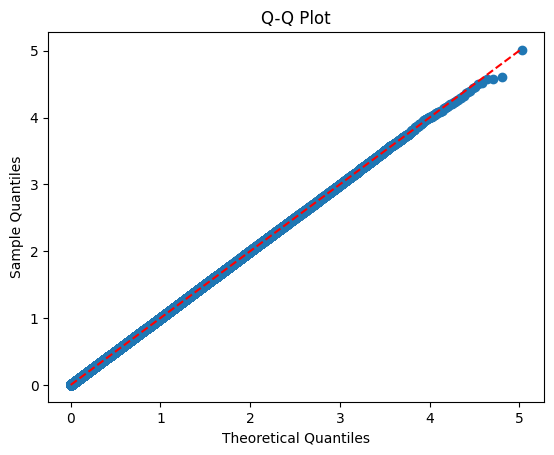

In [28]:
def get_c_ppf():
    x_fine = np.linspace(0, 10, 100000)
    cdf_values = c_cdf(x_fine)
    return scipy.interpolate.interp1d(cdf_values, x_fine, bounds_error=False, fill_value=(0, 10))
c_ppf = get_c_ppf()
drawqq(c_sample, c_ppf)

In [29]:
print(f"{np.mean(c_sample)} - średnia próbkowa, {np.var(c_sample)} - wariancja próbkowa")
mean = scipy.integrate.quad(lambda x: x * c_pdf(x), 0, np.inf)[0]
var = scipy.integrate.quad(lambda x: np.power(x, 2) * c_pdf(x), 0, np.inf)[0] - np.power(mean, 2)
print(f"{mean} - średnia teoretyczna, {var} - wariancja teoretyczna")

0.7977797797756391 - średnia próbkowa, 0.36268259044909607 - wariancja próbkowa
0.7978845608028651 - średnia teoretyczna, 0.36338022763242017 - wariancja teoretyczna


## Zadanie 4. 
Metoda Boxa-Mullera

In [30]:
def box_muller(size, mean=2, variance=2):
    u1 = np.random.uniform(0,1,size=size//2)
    u2 = np.random.uniform(0,1,size=size//2)
    z0 = np.sqrt(-2 * np.log(u1)) * np.cos(2 * np.pi * u2) * np.sqrt(variance) + mean
    z1 = np.sqrt(-2 * np.log(u1)) * np.sin(2 * np.pi * u2) * np.sqrt(variance) + mean
    
    return np.concatenate([z0, z1])

print(box_muller(100))

[ 2.65634249  2.07023624  1.73316626  2.51364844  2.08819248 -0.89130765
  1.08145477  2.68775663  1.36216532 -0.60948441  2.51055007  2.081953
 -0.12324587  1.86491772  2.3752002   2.34409674  2.62729672  2.94249104
  3.69817664  2.3494095   3.19849614  1.10052947  2.5364656   4.4238115
  1.45356339  3.39816757  1.30490285  0.90310373  3.71800174  2.1759788
  2.10576216  2.15278789  3.65651482  0.20038815  1.85282657  3.99282347
  1.14932052  2.20493305  3.023133    4.10734735  2.3887694   2.51362175
  3.91138946 -0.68412649  2.26098032  2.16310316  1.97006768  3.394137
  1.60806541  2.3566259   0.65512913  0.39472541  1.91137134  4.63062547
  4.83981535  3.08838282  3.11572267  2.92079141  3.16529448  1.09588877
  3.50995606  1.78633989  2.23646927  2.10207986  0.33460753  2.52939548
  1.3914333   4.92083633  3.64421658  1.41142531  2.4683077   2.16439901
  2.89281769  1.16532536  2.6348639   0.36282745  0.79587845  1.28395198
  1.59123226  3.86462241  2.45009972  0.61626927  2.40560

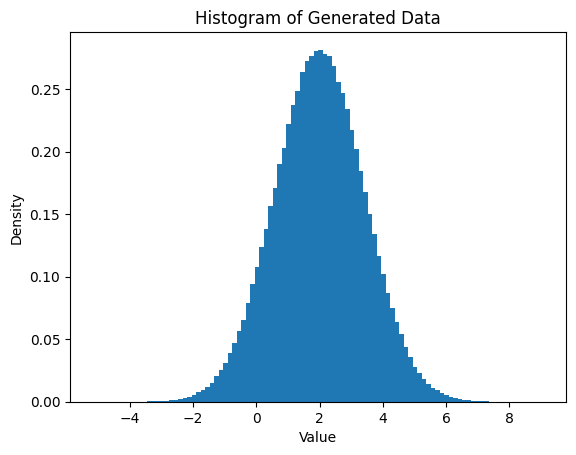

In [31]:
plt.hist(box_muller(1000000), bins=100, density=True)
plt.xlabel('Value')
plt.ylabel('Density')
plt.title('Histogram of Generated Data')
plt.show()

In [32]:
def box_muller_p(size, mean=2, variance=2):
    u0 = np.random.uniform(-1,1,size=size)
    u1 = np.random.uniform(-1,1,size=size)
    while True:
        mask = (u0**2 + u1**2 < 1) 
        u0[~mask] = np.random.uniform(-1, 1, size=np.sum(~mask))
        u1[~mask] = np.random.uniform(-1, 1, size=np.sum(~mask))
        if np.sum(mask) >= size:
            break
    z0 = np.sqrt(-2 * np.log(u0[mask]**2 + u1[mask]**2) / (u0[mask]**2 + u1[mask]**2)) * u0[mask] * np.sqrt(variance) + mean
    z1 = np.sqrt(-2 * np.log(u0[mask]**2 + u1[mask]**2) / (u0[mask]**2 + u1[mask]**2)) * u1[mask] * np.sqrt(variance) + mean
    return np.concatenate([z0, z1])

print(box_muller_p(100))

[ 2.74394766  1.08110962  2.08055487  3.07966426  1.72341885  2.65939523
  2.44518816  0.99766021  1.86368977  3.08321911  2.30841301  0.57038565
  2.68341624 -0.40561948  4.61918213  3.31853183  4.24350679  0.34662575
  2.21478211 -0.8237426   5.09901131  2.30098757  3.39790174  1.16530265
  1.91006503  3.7771799   3.82589458  2.01098823  3.08656095  2.77883382
  2.06339639 -0.07050104  2.39691644  3.65601811  2.07285117  2.57200028
  4.64214289  1.58431444  2.38107757  1.89507443  1.22630447  1.39166803
  4.22437399  0.34090288  2.79598134  2.85678771  1.33062994  2.80936914
  1.21720548  1.8361935   1.93021992  1.94159785  2.84309559  2.74420046
  1.20758146  2.33588254  0.7968709   3.37164942  2.16686186 -0.20912406
  0.97081709  4.88831323  4.14423567 -1.11315328  1.00830079  1.44667335
  1.55767605  5.47247557 -0.54019063  3.67341698  2.86138801  2.43185385
  1.97135317  0.82643444  0.74475684  0.69960444  3.27467302  2.42723625
  2.84353588  3.09657395  1.73325362  1.03500225  2

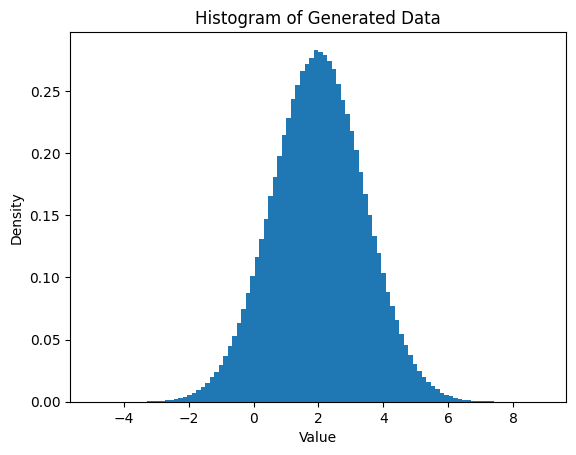

In [33]:
plt.hist(box_muller_p(1000000), bins=100, density=True)
plt.xlabel('Value')
plt.ylabel('Density')
plt.title('Histogram of Generated Data')
plt.show()

## Zadanie 5 
Porównanie metody biegunowej boxa mullera ze zwykłą metodą boxa mullera

Text(0, 0.5, 'Time (seconds)')

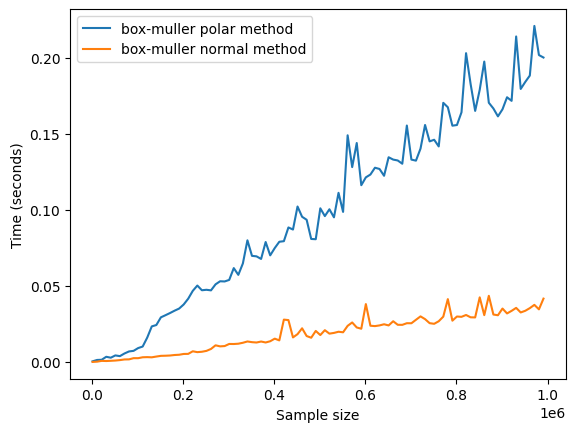

In [34]:
import time 
polar_time =[]
normal_time = []
for i in range(1000, 1000000,10000):
    start_time = time.time()
    box_muller_p(i)
    polar_time.append(time.time() - start_time)
    start_time = time.time()
    box_muller(i)   
    normal_time.append(time.time() - start_time)

plt.plot(range(1000, 1000000,10000), polar_time, label="box-muller polar method")
plt.plot(range(1000, 1000000,10000), normal_time, label="box-muller normal method")
plt.legend()
plt.xlabel("Sample size")
plt.ylabel("Time (seconds)")

## Zadanie 7. 
Całki monte carlo 

In [37]:
def pi_estimation(size):
    u0 = np.random.uniform(-1,1,size=size)
    u1 = np.random.uniform(-1,1,size=size)
    mask = (u0**2 + u1**2 < 1) 
    return 4 * np.sum(mask) / size

print(pi_estimation(100000), np.pi)

3.14156 3.141592653589793


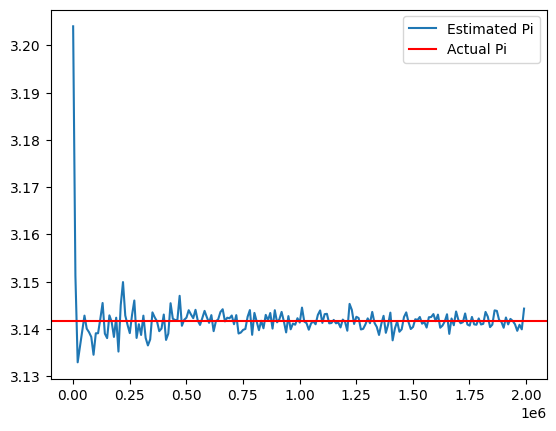

In [43]:
pi_values = []
for i in range(1000, 2000000, 10000):
    pi_values.append(pi_estimation(i))
plt.plot(range(1000, 2000000, 10000), pi_values, label="Estimated Pi")
plt.axhline(y=np.pi, color='r', linestyle='-', label="Actual Pi")
plt.legend()
plt.show() 

In [57]:
def integral_estimation(func, a, b, size):
    x = np.random.uniform(a, b, size=size)
    y = func(x)
    return (b - a) * np.mean(y)

print(integral_estimation(lambda x: np.exp(x**2), 0, 1, 2000000),scipy.integrate.quad(lambda x: np.exp(x**2), 0, 1)[0])

1.462682459454206 1.4626517459071815


## Zadanie 6. 
Rozkład Choleskiego


[[ 1.   0.7 -0.3]
 [ 0.7  1.   0.4]
 [-0.3  0.4  1. ]]


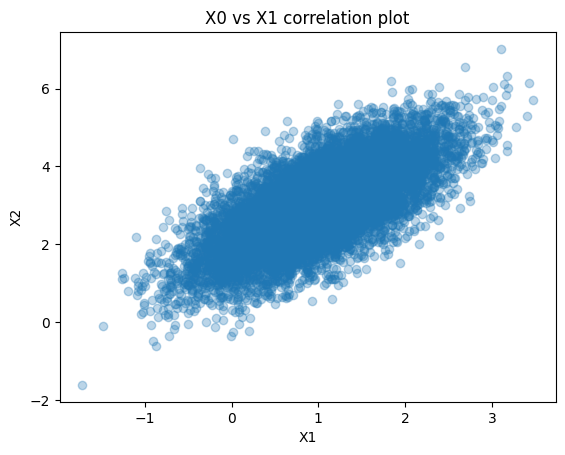

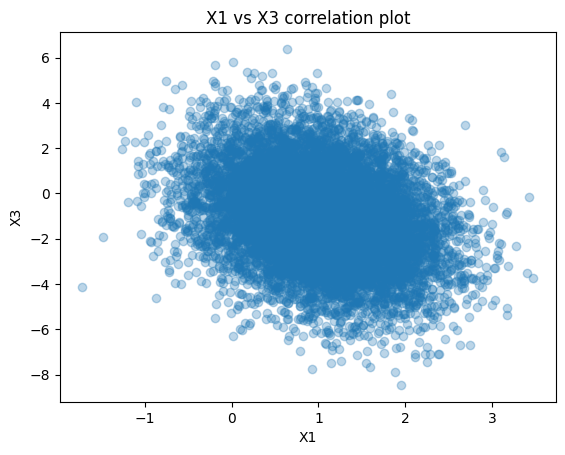

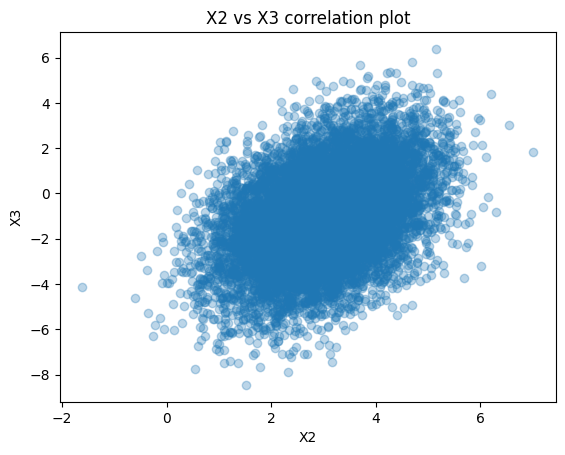

10000
1.0094564784776447 3.006078943349492 -1.0153831668083435  mean
0.48973350116668773 0.9973144454916549 4.001471774852462  variances
[[ 1.          0.69782518 -0.29228767]
 [ 0.69782518  1.          0.40887735]
 [-0.29228767  0.40887735  1.        ]]  empirical correlation matrix


In [77]:
means = np.array([1,3,-1])
var = np.array([0.5, 1, 4])
Q = np.array([[1,0.7,-0.3],[0.7,1,0.4], [-0.3,0.4,1]])
print(Q)
L = np.linalg.cholesky(Q)
Z = np.random.normal(size=(3, 10000))
X = L @ Z
X = X * np.sqrt(var)[:, np.newaxis] + means[:, np.newaxis]
plt.scatter(X[0], X[1], alpha=0.3)
plt.xlabel('X1')
plt.ylabel('X2')
plt.title('X0 vs X1 correlation plot')
plt.show()

plt.scatter(X[0], X[2], alpha=0.3)
plt.xlabel('X1')
plt.ylabel('X3')
plt.title('X1 vs X3 correlation plot')
plt.show()

plt.scatter(X[1], X[2], alpha=0.3)
plt.xlabel('X2')
plt.ylabel('X3')
plt.title('X2 vs X3 correlation plot')
plt.show()
print(len(X[1]))
print(np.mean(X[0]), np.mean(X[1]), np.mean(X[2]), " mean")
print(np.var(X[0]), np.var(X[1]), np.var(X[2]), " variances")
print(np.corrcoef(X), " empirical correlation matrix")


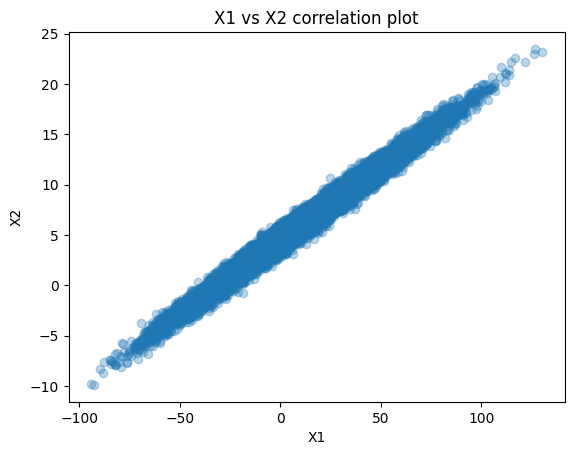

12.856760437582658 6.385777176114806  mean
900.679906978102 19.53478096211827  variances
[[1.         0.99068917]
 [0.99068917 1.        ]]  empirical correlation matrix


In [80]:
means = np.array([2,3])
var = np.array([30,1])

Q = np.array([[1,0.8], [0.8,1]])
L = np.linalg.cholesky(Q)
Z = np.array([box_muller(20000, mean=means[0], variance=var[0]), box_muller(20000, mean=means[1], variance=var[1])])
X = L @ Z
X = X * np.sqrt(var)[:, np.newaxis] + means[:, np.newaxis]
plt.scatter(X[0], X[1], alpha=0.3)
plt.xlabel('X1')
plt.ylabel('X2')
plt.title('X1 vs X2 correlation plot')
plt.show()
print(np.mean(X[0]), np.mean(X[1]), " mean")
print(np.var(X[0]), np.var(X[1]), " variances")
print(np.corrcoef(X), " empirical correlation matrix")